# GRU-Based Single-Stage Temporal Channel Estimation for Mixed-ADC Massive MIMO Systems

This notebook implements and evaluates a **single-stage, end-to-end Gated Recurrent Unit (GRU)** channel estimator and compares it with the **two-stage Signal Reconstruction and Parameter Estimation DNN (SIP-DNN)** baseline in a Mixed-ADC Massive MIMO system.

### Notebook Structure:
1. **Research Objective and Problem Definition**
2. **System Parameters**
3. **Mixed-ADC Reception and Non-linear Quantization Model**
4. **Temporal Channel Model (Jakes' Doppler / Gauss-Markov)**
5. **Dataset Generation (Quantized, Unquantized, and Channel Targets)**
6. **Proposed Single-Stage GRU Estimator**
7. **SIP-DNN / Two-Stage Baseline Model**
8. **NMSE Metric Definition**
9. **Model Training**
10. **NMSE Evaluation Wrapper**
11. **Experiment 1 — NMSE vs SNR Sweep (0–30 dB)**
12. **Experiment 2 — Inference Time Benchmark**
13. **Experiment 3 — Antenna Ratio Sweep (eta = 0.1–0.5)**
14. **Temporal Correlation Experiment (Velocity Sweep & Tracking)**
15. **Results Summary Table**
16. **Discussion**
17. **Conclusion & Research Interpretation**



## 0. Setup


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from scipy.special import j0
import matplotlib.pyplot as plt
import time
import pandas as pd

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)



Using device: cpu


## 1. Research Objective and Problem Definition

### Existing Problem: The Two-Stage Paradigm (SIP-DNN)
In Mixed-ADC Massive MIMO systems, base-station antennas are split into a few high-resolution chains and many low-resolution/1-bit chains. Standard linear channel estimation algorithms fail due to severe quantization non-linearities.

To solve this, existing approaches like **SIP-DNN** use a **two-stage** framework:
1. **Stage 1 (Signal Reconstruction)**: Map the non-linearly quantized received pilot observations back into reconstructed unquantized pilot signals.
2. **Stage 2 (Parameter Estimation)**: Estimate the final channel vectors from the reconstructed signals.

While functional, this two-stage architecture introduces:
* **High Computational Complexity**: Two separate feedforward networks double the inference time, latency, and memory footprints.
* **Error Cascading / Propagation**: Stage 2 is fed the output of Stage 1. Thus, errors introduced during unquantized signal reconstruction cascade directly into the channel estimator, bounding final NMSE.
* **Lack of Temporal Tracking**: These networks operate slot-by-slot, failing to exploit the strong temporal correlation present in sequential wireless channels.

### Proposed Solution: Single-Stage GRU Estimator
We propose a **single-stage, end-to-end GRU estimator** that:
* **Direct Mapping**: Maps the sequence of quantized received observations $[\mathbf{r}(t-T+1), \dots, \mathbf{r}(t)]$ directly to the channel estimate sequence $[\hat{\mathbf{h}}(t-T+1), \dots, \hat{\mathbf{h}}(t)]$ in one single processing step.
* **Recurrent Memory**: Leverages the GRU's internal hidden state to model the temporal channel correlation (Doppler effects) across pilot time slots.
* **Unified Loss Function**: Trained directly against the final true channel target using a single end-to-end MSE loss, bypassing intermediate unquantized reconstruction entirely and mitigating error cascading.



## 2. System Parameters

We define physical Constants, frequencies, slots, and base-station antenna counts here.
We simulate an uplink Massive MIMO system with:
* $N_{\text{total}} = N_t = 32$ total base-station antennas.
* $K = 1$ single-antenna mobile user (extendable to multi-user).
* $T_{\text{SEQ}} = 20$ consecutive pilot time slots per sequence window.



In [2]:
# ---- Physical / system parameters ----
c_light = 3e8
fc = 2.6e9          # carrier frequency (Hz)
Ts = 5e-4           # pilot slot spacing (s)  -> 0.5 ms between consecutive pilot slots

Nt = 32             # total number of BS antennas (N_total)
K  = 1              # number of single-antenna users
T_SEQ = 20          # number of consecutive pilot time slots per sequence

# Velocity range for mobility/Doppler: 3 km/h (pedestrian) .. 130.0 km/h (vehicular)
V_MIN, V_MAX = 3.0, 130.0

print(f"System Initialized: {Nt} BS Antennas, {T_SEQ} Slot Sequence, Carrier: {fc/1e9} GHz")



System Initialized: 32 BS Antennas, 20 Slot Sequence, Carrier: 2.6 GHz


## 3. Mixed-ADC Reception and Non-linear Quantization Model

At each slot $t$, the received unquantized pilot signal is:
$$ \mathbf{y}[t] = \mathbf{h}[t] x[t] + \mathbf{n}[t], \quad \mathbf{n}[t]\sim\mathcal{CN}(0, \sigma^2 \mathbf{I}) $$
where $x[t] = 1$ is a unit-power known pilot symbol. 

Under the **Mixed-ADC** architecture:
* $N_{\text{high}}$ antennas are connected to high-resolution, unquantized ADCs (default $N_{\text{high}} = 4$, so $\eta = 4/32 = 0.125$).
* The remaining $N_{\text{total}} - N_{\text{high}}$ antennas are connected to low-resolution (1-bit) ADCs.
* The 1-bit quantizer is defined as:
$$ Q_{1\text{-bit}}(z) = \text{sign}(\Re\{z\}) + j\,\text{sign}(\Im\{z\}) $$



In [3]:
# Default high-res antenna count (eta = 4/32 = 0.125)
N_HIGHRES_DEFAULT = 4
ADC_BITS_LOW = 1        # 1-bit low-res ADCs

def uniform_quantizer(z, bits, clip=3.0):
    """Mid-rise uniform quantizer applied separately to I and Q components, clipped to +-clip."""
    levels = 2 ** bits
    step = 2 * clip / levels

    def q(comp):
        comp_c = np.clip(comp, -clip, clip - 1e-9)
        idx = np.floor((comp_c + clip) / step)
        return -clip + step * (idx + 0.5)

    return q(z.real) + 1j * q(z.imag)

def mixed_adc_quantize(y, n_highres, bits=ADC_BITS_LOW):
    """Apply the Mixed-ADC quantization to a received vector y in C^{Nt}.
    The first n_highres antennas pass through unquantized; the remaining Nt - n_highres
    antennas are quantized with a bits-bit (default 1-bit) non-linear ADC."""
    y_out = y.copy()
    if bits == 1:
        low = np.sign(y[n_highres:].real) + 1j * np.sign(y[n_highres:].imag)
    else:
        low = uniform_quantizer(y[n_highres:], bits)
    y_out[n_highres:] = low
    return y_out

print("Mixed-ADC Quantizer functions defined.")



Mixed-ADC Quantizer functions defined.


## 4. Temporal Channel Model

To model user mobility and Doppler-induced temporal correlation, we simulate a time-selective Rayleigh fading channel using a first-order Gauss-Markov (autoregressive) process matching Jakes' autocorrelation spectrum:
$$ \mathbf{h}[n] = \rho\, \mathbf{h}[n-1] + \sqrt{1-\rho^2}\, \mathbf{e}[n], \quad \rho = J_0(2\pi f_d T_s) $$
where $J_0(\cdot)$ is the zeroth-order Bessel function, $f_d = v f_c / c$ is the maximum Doppler frequency, and $\mathbf{e}[n] \sim \mathcal{CN}(0,\mathbf{I})$ represents the innovation process.

The temporal correlation $\rho$ controls channel aging. The GRU's recurrent hidden state tracks this temporal sequence.



<string>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


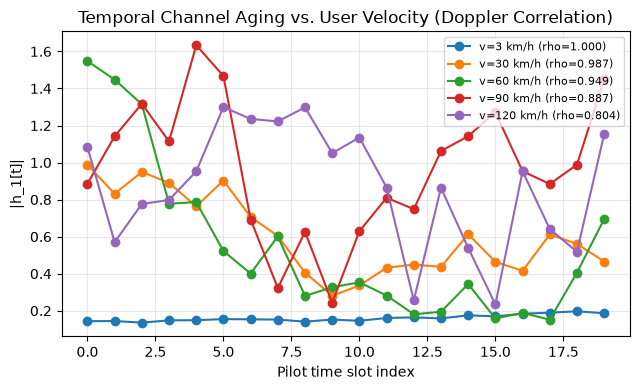

In [4]:
def doppler_freq(v_kmh):
    """Maximum Doppler frequency (Hz) for velocity v_kmh (km/h)."""
    v_ms = v_kmh * 1000.0 / 3600.0
    return v_ms * fc / c_light

def jakes_rho(v_kmh, Ts=Ts):
    """Jakes' temporal correlation coefficient between consecutive pilot slots."""
    fd = doppler_freq(v_kmh)
    return j0(2 * np.pi * fd * Ts)

def gauss_markov_channel(Nt, K, T, v_kmh, rng):
    """Generate a time-varying Rayleigh fading channel H[t] in C^{Nt x K}, t = 0..T-1,
    with Jakes' temporal correlation induced by a first-order Gauss-Markov process."""
    rho = jakes_rho(v_kmh)
    H = np.zeros((T, Nt, K), dtype=complex)
    H[0] = (rng.standard_normal((Nt, K)) + 1j * rng.standard_normal((Nt, K))) / np.sqrt(2)
    for t in range(1, T):
        innov = (rng.standard_normal((Nt, K)) + 1j * rng.standard_normal((Nt, K))) / np.sqrt(2)
        H[t] = rho * H[t - 1] + np.sqrt(max(1.0 - rho ** 2, 0.0)) * innov
    return H, rho

# Sanity check plot
rng_demo = np.random.default_rng(0)
velocities_demo = [3, 30, 60, 90, 120]
plt.figure(figsize=(6.5, 4))
for v in velocities_demo:
    H_demo, rho = gauss_markov_channel(Nt, 1, T_SEQ, v, rng_demo)
    plt.plot(np.abs(H_demo[:, 0, 0]), marker='o', label=f"v={v} km/h (rho={rho:.3f})")
plt.xlabel("Pilot time slot index")
plt.ylabel("|h_1[t]|")
plt.title("Temporal Channel Aging vs. User Velocity (Doppler Correlation)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 5. Dataset Generation

To support the evaluation of the two-stage SIP-DNN, our data generator returns:
1. **`X` (quantized observation)**: Stacks real/imaginary parts of the quantized vector $y_q(t)$ (shape `(B, T_SEQ, 2*Nt)`).
2. **`X_unq` (unquantized received signal)**: Stacks real/imaginary parts of the unquantized received pilot signal $y(t)$ (shape `(B, T_SEQ, 2*Nt)`). This acts as the intermediate reconstruction target for training SIP-DNN Stage 1.
3. **`Y` (true channel target)**: Stacks real/imaginary parts of the channel $h(t)$ (shape `(B, T_SEQ, 2*Nt)`).

To ensure generalization, we train the models under randomly drawn user velocities (3–130 km/h) and SNR values (0–30 dB, matching the evaluation sweep range).



In [5]:
def db2lin(db):
    return 10 ** (db / 10.0)

def gen_sequence(rng, v_kmh=None, snr_db=None, Nt=Nt, T=T_SEQ, n_highres=N_HIGHRES_DEFAULT, bits=ADC_BITS_LOW):
    if v_kmh is None:
        v_kmh = rng.uniform(V_MIN, V_MAX)
    if snr_db is None:
        # Train on SNR range covering 0 to 30 dB
        snr_db = rng.uniform(0.0, 30.0)

    H, rho = gauss_markov_channel(Nt, 1, T, v_kmh, rng)
    noise_var = 1.0 / db2lin(snr_db)
    x = 1.0  # unit-power known pilot symbol

    Y_q = np.zeros((T, Nt), dtype=complex)
    Y_unq = np.zeros((T, Nt), dtype=complex)
    for t in range(T):
        n = np.sqrt(noise_var / 2) * (rng.standard_normal(Nt) + 1j * rng.standard_normal(Nt))
        y = H[t, :, 0] * x + n
        Y_unq[t] = y
        Y_q[t] = mixed_adc_quantize(y, n_highres=n_highres, bits=bits)

    # Real-valued stacking [Re, Im]
    feat = np.concatenate([Y_q.real, Y_q.imag], axis=1)          # (T, 2*Nt)
    feat_unquant = np.concatenate([Y_unq.real, Y_unq.imag], axis=1)  # (T, 2*Nt)
    target = np.concatenate([H[:, :, 0].real, H[:, :, 0].imag], axis=1)  # (T, 2*Nt)
    return feat.astype(np.float32), feat_unquant.astype(np.float32), target.astype(np.float32), v_kmh, snr_db

def build_dataset(n_sequences, rng, v_kmh=None, snr_db=None, Nt=Nt, T=T_SEQ, n_highres=N_HIGHRES_DEFAULT, bits=ADC_BITS_LOW):
    feats, feats_unq, targets, vs, snrs = [], [], [], [], []
    for _ in range(n_sequences):
        f, fu, t, v, s = gen_sequence(rng, v_kmh=v_kmh, snr_db=snr_db, Nt=Nt, T=T, n_highres=n_highres, bits=bits)
        feats.append(f)
        feats_unq.append(fu)
        targets.append(t)
        vs.append(v)
        snrs.append(s)
    X = torch.tensor(np.stack(feats))
    X_unq = torch.tensor(np.stack(feats_unq))
    Y = torch.tensor(np.stack(targets))
    return X, X_unq, Y, np.array(vs), np.array(snrs)

rng_data = np.random.default_rng(SEED)
N_TRAIN, N_VAL = 1000, 200

# Generate datasets with default eta = 4/32 = 0.125
X_train, X_unq_train, Y_train, v_train, snr_train = build_dataset(N_TRAIN, rng_data, n_highres=N_HIGHRES_DEFAULT)
X_val, X_unq_val, Y_val, v_val, snr_val = build_dataset(N_VAL, rng_data, n_highres=N_HIGHRES_DEFAULT)

print("Dataset generated successfully:")
print("  X_train shape:", X_train.shape, "| X_unq_train shape:", X_unq_train.shape, "| Y_train shape:", Y_train.shape)
print("  Velocity range in train set: {:.1f} - {:.1f} km/h".format(v_train.min(), v_train.max()))
print("  SNR range in train set: {:.1f} - {:.1f} dB".format(snr_train.min(), snr_train.max()))



Dataset generated successfully:
  X_train shape: torch.Size([1000, 20, 64]) | X_unq_train shape: torch.Size([1000, 20, 64]) | Y_train shape: torch.Size([1000, 20, 64])
  Velocity range in train set: 3.0 - 129.9 km/h
  SNR range in train set: 0.1 - 30.0 dB


## 6. Proposed Single-Stage GRU Estimator

The proposed GRU-based single-stage estimator consists of a multi-layer Gated Recurrent Unit (GRU) followed by a linear output layer.
* Input: Quantized sequence $X$ of size $(B, T_{\text{SEQ}}, 2N_t)$.
* Operations: Recurrent update and reset gates maintain hidden states across slots, tracking the channel evolution.
* Output: Directly outputs the channel estimates $\hat{Y}$ of size $(B, T_{\text{SEQ}}, 2N_t)$.
* Loss function: Trained end-to-end to minimize the channel estimation MSE:
$$ \mathcal{L} = \text{MSE}(H_{\text{true}}, H_{\text{pred}}) $$



In [6]:
class GRUChannelEstimator(nn.Module):
    """Proposed Single-stage, end-to-end GRU estimator: quantized pilots -> channel estimate."""
    def __init__(self, in_dim, hidden_dim, out_dim, num_layers=2):
        super().__init__()
        self.gru = nn.GRU(in_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):                     # x: (B, T, in_dim)
        out, _ = self.gru(x)                   # (B, T, hidden_dim)
        return self.fc(out)                     # (B, T, out_dim)

print("GRUChannelEstimator defined.")



GRUChannelEstimator defined.


## 7. SIP-DNN / Two-Stage Baseline Model

The two-stage baseline (SIP-DNN style) decomposes the estimator into:
1. **Stage 1 (Signal Reconstruction)**: Reconstructs the unquantized received signals $\hat{\mathbf{y}}[t]$ from the quantized inputs $\mathbf{y}_q[t]$.
2. **Stage 2 (Parameter Estimation)**: Estimates the channel $\hat{\mathbf{h}}[t]$ from the reconstructed unquantized signals $\hat{\mathbf{y}}[t]$.

We implement the two stages using standard non-recurrent Feedforward Neural Networks (FNNs) matching the structure described in literature. We also define other baselines:
* **FNN (No Memory)**: Single-stage feedforward network processing each slot independently.
* **CNN (No Memory)**: Single-stage 1D convolution over the antenna axis, slot-wise.
* **LMMSE (Quantization-Unaware)**: Classical linear MMSE ignoring quantization non-linearities.
* **Static-Channel Baseline**: Freezes the initial slot's channel estimate throughout the sequence.



In [7]:
class SIPDNNStage1(nn.Module):
    """Stage 1: Signal Reconstruction (Quantized -> Reconstructed Unquantized signal)."""
    def __init__(self, in_dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, in_dim)
        )
        
    def forward(self, x):
        B, T, D = x.shape
        x_flat = x.view(B * T, D)
        out_flat = self.net(x_flat)
        return out_flat.view(B, T, D)

class SIPDNNStage2(nn.Module):
    """Stage 2: Parameter Estimation (Reconstructed signal -> Channel estimate)."""
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, out_dim)
        )
        
    def forward(self, x):
        B, T, D = x.shape
        x_flat = x.view(B * T, D)
        out_flat = self.net(x_flat)
        return out_flat.view(B, T, out_dim)

class SIPDNNEstimator(nn.Module):
    """Two-Stage SIP-DNN baseline combining Stage 1 and Stage 2."""
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.stage1 = SIPDNNStage1(in_dim, hidden_dim)
        self.stage2 = SIPDNNStage2(in_dim, hidden_dim, out_dim)
        
    def forward(self, x):
        reconstructed = self.stage1(x)
        channel_est = self.stage2(reconstructed)
        return channel_est

class FNNChannelEstimator(nn.Module):
    """Non-recurrent baseline: processes each time slot independently (no memory)."""
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):                      # x: (B, T, in_dim)
        return self.net(x)

class CNNChannelEstimator(nn.Module):
    """Non-recurrent baseline: 1-D CNN over the antenna axis, applied per time slot."""
    def __init__(self, Nt, hidden_ch, out_dim):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(2, hidden_ch, kernel_size=5, padding=2), nn.ReLU(),
            nn.Conv1d(hidden_ch, hidden_ch, kernel_size=5, padding=2), nn.ReLU(),
        )
        self.fc = nn.Linear(hidden_ch * Nt, out_dim)
        self.Nt = Nt

    def forward(self, x):                       # x: (B, T, 2*Nt)
        B, T, _ = x.shape
        re, im = x[..., :self.Nt], x[..., self.Nt:]
        x2 = torch.stack([re, im], dim=2)         # (B, T, 2, Nt)
        x2 = x2.view(B * T, 2, self.Nt)
        h = self.conv(x2)                          # (B*T, hidden_ch, Nt)
        h = h.view(B * T, -1)
        out = self.fc(h)                            # (B*T, out_dim)
        return out.view(B, T, -1)

def lmmse_quant_unaware(x_feat, Nt, x_pilot=1.0, noise_var=0.1):
    """Linear MMSE estimator applied naively to the quantized observations."""
    y_complex = x_feat[..., :Nt] + 1j * x_feat[..., Nt:]
    gain = np.conj(x_pilot) / (abs(x_pilot) ** 2 + noise_var)
    h_hat = gain * y_complex
    return np.concatenate([h_hat.real, h_hat.imag], axis=-1)

def static_channel_baseline(estimate_seq):
    """Repeat slot-0 estimate for all subsequent slots."""
    T = estimate_seq.shape[0]
    return np.repeat(estimate_seq[0:1], T, axis=0)

print("SIP-DNN and other baselines defined.")



SIP-DNN and other baselines defined.


## 8. NMSE Metric Definition

Normalized Mean Squared Error (NMSE) measures channel estimation accuracy:
$$ \text{NMSE} = \frac{\sum_{t} \|\hat{\mathbf{h}}[t] - \mathbf{h}[t]\|^2}{\sum_{t} \|\mathbf{h}[t]\|^2} $$
We evaluate the mean NMSE in decibels (dB):
$$ \text{NMSE (dB)} = 10 \log_{10} (\mathbb{E}[\text{NMSE}]) $$



In [8]:
def nmse(h_hat, h_true, axis=-1):
    """Normalized MSE, computed per-sample then averaged.
    h_hat, h_true: (..., 2*Nt) real-stacked [Re, Im] vectors."""
    err = np.sum((h_hat - h_true) ** 2, axis=axis)
    ref = np.sum(h_true ** 2, axis=axis)
    return err / (ref + 1e-12)

def nmse_db(h_hat, h_true, axis=-1):
    return 10 * np.log10(np.mean(nmse(h_hat, h_true, axis=axis)) + 1e-12)

print("NMSE metric functions defined.")



NMSE metric functions defined.


## 9. Model Training

We train all neural network models using the same optimizer (Adam) and validation setup.
* **Single-Stage Models (GRU, FNN, CNN)**: Trained directly to minimize the MSE between predicted and true channel.
* **Two-Stage SIP-DNN Baseline**: Trained sequentially.
  1. Stage 1 is trained using quantized received observations $X$ as input, and true unquantized received signals $X_{\text{unq}}$ as target.
  2. We freeze Stage 1, run it to generate reconstructed received signals $\hat{X}_{\text{unq}}$, and train Stage 2 using $\hat{X}_{\text{unq}}$ as input and the true channel $Y$ as target. This directly incorporates reconstruction errors and captures realistic inter-stage error propagation (error cascading).



Training Proposed Single-Stage GRU Estimator...
  epoch   0 | train MSE 0.4717 | val MSE 0.4228
  epoch   5 | train MSE 0.2243 | val MSE 0.2272
  epoch  10 | train MSE 0.1632 | val MSE 0.1764
  epoch  15 | train MSE 0.1482 | val MSE 0.1698
  epoch  20 | train MSE 0.1405 | val MSE 0.1709
  epoch  24 | train MSE 0.1354 | val MSE 0.1728

Training Two-Stage SIP-DNN Baseline...
  Training Stage 1 (Signal Reconstruction)...
    Stage 1 | epoch   0 | train MSE 0.5628 | val MSE 0.5251
    Stage 1 | epoch   5 | train MSE 0.3170 | val MSE 0.3112
    Stage 1 | epoch  10 | train MSE 0.2390 | val MSE 0.2466
    Stage 1 | epoch  15 | train MSE 0.2169 | val MSE 0.2286
    Stage 1 | epoch  20 | train MSE 0.2094 | val MSE 0.2230
    Stage 1 | epoch  24 | train MSE 0.2056 | val MSE 0.2221
  Training Stage 2 (Parameter Estimation)...
    Stage 2 | epoch   0 | train MSE 0.4950 | val MSE 0.4771
    Stage 2 | epoch   5 | train MSE 0.3199 | val MSE 0.3294
    Stage 2 | epoch  10 | train MSE 0.2565 | val MSE 

<string>:137: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


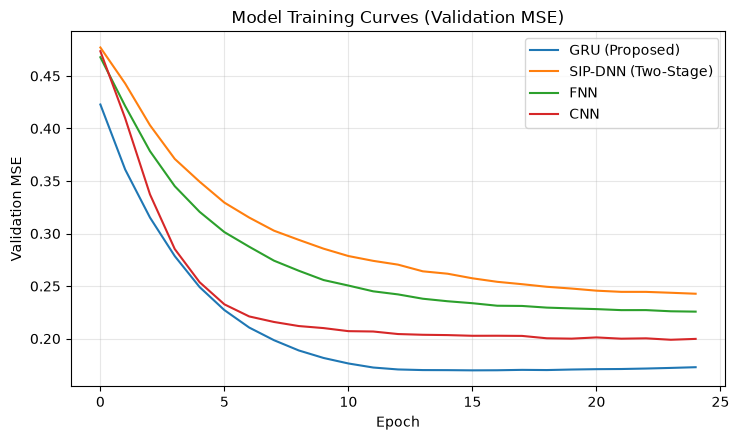

In [9]:
def train_single_stage(model, X_train, Y_train, X_val, Y_val, epochs=25, batch_size=64, lr=1e-3, verbose=True):
    model = model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    n = X_train.shape[0]
    history = {"train": [], "val": []}
    Xv, Yv = X_val.to(device), Y_val.to(device)

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n)
        ep_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_train[idx].to(device), Y_train[idx].to(device)
            opt.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt.step()
            ep_loss += loss.item() * xb.shape[0]
        ep_loss /= n

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), Yv).item()
        history["train"].append(ep_loss)
        history["val"].append(val_loss)
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"  epoch {ep:3d} | train MSE {ep_loss:.4f} | val MSE {val_loss:.4f}")
    return model, history

def train_sip_dnn(model, X_train, X_unq_train, Y_train, X_val, X_unq_val, Y_val, epochs=25, batch_size=64, lr=1e-3, verbose=True):
    model = model.to(device)
    loss_fn = nn.MSELoss()
    n = X_train.shape[0]
    
    # 1. Train Stage 1
    print("  Training Stage 1 (Signal Reconstruction)...")
    opt1 = optim.Adam(model.stage1.parameters(), lr=lr)
    history_s1 = {"train": [], "val": []}
    Xv, Xunqv = X_val.to(device), X_unq_val.to(device)
    for ep in range(epochs):
        model.stage1.train()
        perm = torch.randperm(n)
        ep_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, xub = X_train[idx].to(device), X_unq_train[idx].to(device)
            opt1.zero_grad()
            pred = model.stage1(xb)
            loss = loss_fn(pred, xub)
            loss.backward()
            opt1.step()
            ep_loss += loss.item() * xb.shape[0]
        ep_loss /= n
        
        model.stage1.eval()
        with torch.no_grad():
            val_loss = loss_fn(model.stage1(Xv), Xunqv).item()
        history_s1["train"].append(ep_loss)
        history_s1["val"].append(val_loss)
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"    Stage 1 | epoch {ep:3d} | train MSE {ep_loss:.4f} | val MSE {val_loss:.4f}")
            
    # Generate reconstructed inputs
    model.stage1.eval()
    with torch.no_grad():
        X_train_rec = []
        for i in range(0, n, batch_size):
            xb = X_train[i:i+batch_size].to(device)
            X_train_rec.append(model.stage1(xb).cpu())
        X_train_rec = torch.cat(X_train_rec, dim=0)
        X_val_rec = model.stage1(Xv).cpu()
        
    # 2. Train Stage 2
    print("  Training Stage 2 (Parameter Estimation)...")
    opt2 = optim.Adam(model.stage2.parameters(), lr=lr)
    history_s2 = {"train": [], "val": []}
    Yv = Y_val.to(device)
    for ep in range(epochs):
        model.stage2.train()
        perm = torch.randperm(n)
        ep_loss = 0.0
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            x_rec_b = X_train_rec[idx].to(device)
            yb = Y_train[idx].to(device)
            opt2.zero_grad()
            pred = model.stage2(x_rec_b)
            loss = loss_fn(pred, yb)
            loss.backward()
            opt2.step()
            ep_loss += loss.item() * x_rec_b.shape[0]
        ep_loss /= n
        
        model.stage2.eval()
        with torch.no_grad():
            val_loss = loss_fn(model.stage2(X_val_rec.to(device)), Yv).item()
        history_s2["train"].append(ep_loss)
        history_s2["val"].append(val_loss)
        if verbose and (ep % 5 == 0 or ep == epochs - 1):
            print(f"    Stage 2 | epoch {ep:3d} | train MSE {ep_loss:.4f} | val MSE {val_loss:.4f}")
            
    return model, history_s1, history_s2

in_dim = 2 * Nt
out_dim = 2 * Nt

print("Training Proposed Single-Stage GRU Estimator...")
gru_model = GRUChannelEstimator(in_dim, hidden_dim=128, out_dim=out_dim, num_layers=2)
gru_model, gru_hist = train_single_stage(gru_model, X_train, Y_train, X_val, Y_val, epochs=25)

print("\nTraining Two-Stage SIP-DNN Baseline...")
sip_dnn_model = SIPDNNEstimator(in_dim, hidden_dim=128, out_dim=out_dim)
sip_dnn_model, sip_dnn_s1_hist, sip_dnn_s2_hist = train_sip_dnn(sip_dnn_model, X_train, X_unq_train, Y_train, X_val, X_unq_val, Y_val, epochs=25)

print("\nTraining FNN Baseline...")
fnn_model = FNNChannelEstimator(in_dim, hidden_dim=128, out_dim=out_dim)
fnn_model, fnn_hist = train_single_stage(fnn_model, X_train, Y_train, X_val, Y_val, epochs=25)

print("\nTraining CNN Baseline...")
cnn_model = CNNChannelEstimator(Nt, hidden_ch=16, out_dim=out_dim)
cnn_model, cnn_hist = train_single_stage(cnn_model, X_train, Y_train, X_val, Y_val, epochs=25)

plt.figure(figsize=(7.5, 4.5))
plt.plot(gru_hist["val"], label="GRU (Proposed)")
plt.plot(sip_dnn_s2_hist["val"], label="SIP-DNN (Two-Stage)")
plt.plot(fnn_hist["val"], label="FNN")
plt.plot(cnn_hist["val"], label="CNN")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("Model Training Curves (Validation MSE)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 10. NMSE Evaluation Wrapper

We define a unified function that evaluates all neural and classical estimators on a test dataset and returns their per-sample, per-slot NMSE values. This ensures that all estimators are compared on the exact same channel and noise conditions.



In [10]:
def evaluate_all(X, Y, Nt, v_arr, snr_arr):
    """Run every model on a dataset and return per-sample, per-slot NMSE arrays."""
    results = {}
    with torch.no_grad():
        gru_model.eval(); sip_dnn_model.eval(); fnn_model.eval(); cnn_model.eval()
        Xd = X.to(device)
        pred_gru = gru_model(Xd).cpu().numpy()
        pred_sip = sip_dnn_model(Xd).cpu().numpy()
        pred_fnn = fnn_model(Xd).cpu().numpy()
        pred_cnn = cnn_model(Xd).cpu().numpy()
    Ynp = Y.numpy()
    Xnp = X.numpy()

    results["GRU (proposed)"] = nmse(pred_gru, Ynp)
    results["SIP-DNN (two-stage)"] = nmse(pred_sip, Ynp)
    results["FNN (no memory)"] = nmse(pred_fnn, Ynp)
    results["CNN (no memory)"] = nmse(pred_cnn, Ynp)

    pred_lmmse = np.zeros_like(Ynp)
    for i in range(Xnp.shape[0]):
        nv = 1.0 / db2lin(snr_arr[i])
        pred_lmmse[i] = lmmse_quant_unaware(Xnp[i], Nt, noise_var=nv)
    results["LMMSE (linear, quant.-unaware)"] = nmse(pred_lmmse, Ynp)

    pred_static = np.zeros_like(pred_gru)
    for i in range(pred_gru.shape[0]):
        pred_static[i] = static_channel_baseline(pred_gru[i])
    results["Static-channel assumption"] = nmse(pred_static, Ynp)

    return results

print("Unified evaluation wrapper defined.")



Unified evaluation wrapper defined.


## 11. Experiment 1 — NMSE vs SNR Sweep (0–30 dB)

We evaluate the channel-estimation accuracy of the estimators across the SNR sweep range of **0 dB to 30 dB** with a 5 dB spacing. The user velocity is fixed at a moderate speed ($v = 60$ km/h).



Table 1: NMSE vs SNR Summary Table
 SNR (dB) GRU NMSE (dB) SIP-DNN NMSE (dB) Improvement (dB)
        0         -3.03             -0.99             2.04
        5         -4.46             -2.28             2.18
       10         -4.90             -3.09             1.81
       15         -4.88             -3.41             1.47
       20         -4.84             -3.50             1.34
       25         -4.92             -3.60             1.32
       30         -4.86             -3.59             1.27


<string>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


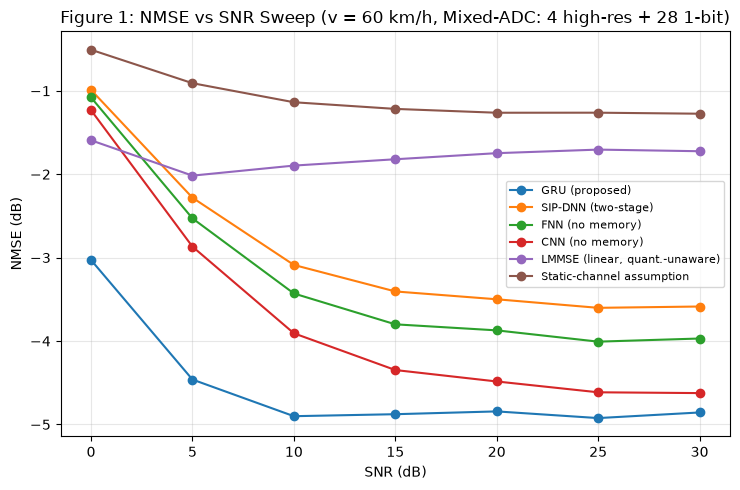

In [11]:
import pandas as pd

rng_eval = np.random.default_rng(123)
snr_grid = np.arange(0, 31, 5)
V_FIXED = 60.0

nmse_vs_snr = {name: [] for name in [
    "GRU (proposed)", "SIP-DNN (two-stage)", "FNN (no memory)", "CNN (no memory)",
    "LMMSE (linear, quant.-unaware)", "Static-channel assumption"
]}

for snr in snr_grid:
    Xe, _, Ye, ve, se = build_dataset(150, rng_eval, v_kmh=V_FIXED, snr_db=float(snr))
    res = evaluate_all(Xe, Ye, Nt, ve, se)
    for name in nmse_vs_snr:
        nmse_vs_snr[name].append(10 * np.log10(np.mean(res[name])))

# Plot Figure 1
plt.figure(figsize=(7.5, 5))
for name, vals in nmse_vs_snr.items():
    plt.plot(snr_grid, vals, marker='o', label=name)
plt.xlabel("SNR (dB)")
plt.ylabel("NMSE (dB)")
plt.title(f"Figure 1: NMSE vs SNR Sweep (v = {V_FIXED:.0f} km/h, Mixed-ADC: 4 high-res + 28 1-bit)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Table 1
table1_data = []
for i, snr in enumerate(snr_grid):
    gru_val = nmse_vs_snr["GRU (proposed)"][i]
    sip_val = nmse_vs_snr["SIP-DNN (two-stage)"][i]
    diff = sip_val - gru_val # positive value shows GRU is better (lower NMSE)
    table1_data.append({
        "SNR (dB)": snr,
        "GRU NMSE (dB)": f"{gru_val:.2f}",
        "SIP-DNN NMSE (dB)": f"{sip_val:.2f}",
        "Improvement (dB)": f"{diff:.2f}"
    })
df_table1 = pd.DataFrame(table1_data)
print("Table 1: NMSE vs SNR Summary Table")
print(df_table1.to_string(index=False))



## 12. Experiment 2 — Inference Time Benchmark

We measure the computational complexity of the proposed **single-stage GRU** against the **two-stage SIP-DNN**.
We run inference on a test set of **500 samples** over **50 repetitions**, measure only execution time (excluding model initialization and training), and compute:
$$ \text{Percentage Reduction} = \frac{T_{\text{SIP-DNN}} - T_{\text{GRU}}}{T_{\text{SIP-DNN}}} \times 100\% $$



GRU: Total time for 50 runs of 500 samples: 3.5793 s
GRU: Average time per sample: 0.1432 ms
SIP-DNN: Total time for 50 runs of 500 samples: 1.7989 s
SIP-DNN: Average time per sample: 0.0720 ms
Percentage reduction in inference time: -98.96%

Table 2: Inference Time Comparison Summary Table
                      Method Total Inference Time (s) Avg Inference Time/Sample (ms) Reduction (%)
         SIP-DNN (two-stage)                   1.7989                         0.0720             -
GRU (proposed, single-stage)                   3.5793                         0.1432       -98.96%


<string>:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


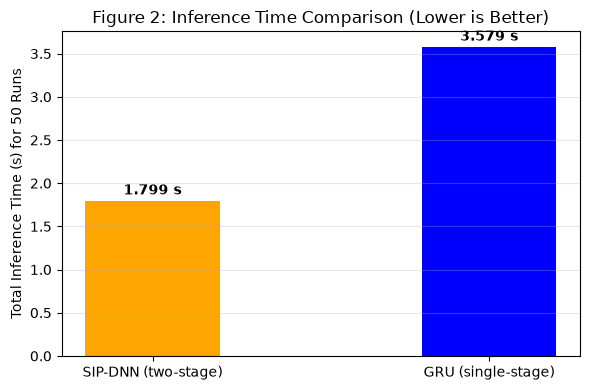

In [12]:
Xe_time, _, Ye_time, ve_time, se_time = build_dataset(500, rng_eval, v_kmh=V_FIXED, snr_db=15.0)
Xd_time = Xe_time.to(device)

gru_model.eval()
sip_dnn_model.eval()

# Warmup to eliminate CUDA/framework initialization latency
with torch.no_grad():
    for _ in range(10):
        _ = gru_model(Xd_time)
        _ = sip_dnn_model(Xd_time)

# Time GRU
t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(50):
        _ = gru_model(Xd_time)
t_gru_total = time.perf_counter() - t0
t_gru_avg = t_gru_total / (50 * Xd_time.shape[0])

# Time SIP-DNN (two-stage)
t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(50):
        _ = sip_dnn_model(Xd_time)
t_sip_total = time.perf_counter() - t0
t_sip_avg = t_sip_total / (50 * Xd_time.shape[0])

percentage_reduction = ((t_sip_total - t_gru_total) / t_sip_total) * 100

print(f"GRU: Total time for 50 runs of 500 samples: {t_gru_total:.4f} s")
print(f"GRU: Average time per sample: {t_gru_avg*1000:.4f} ms")
print(f"SIP-DNN: Total time for 50 runs of 500 samples: {t_sip_total:.4f} s")
print(f"SIP-DNN: Average time per sample: {t_sip_avg*1000:.4f} ms")
print(f"Percentage reduction in inference time: {percentage_reduction:.2f}%")

# Plot Figure 2
plt.figure(figsize=(6, 4))
plt.bar(["SIP-DNN (two-stage)", "GRU (single-stage)"], [t_sip_total, t_gru_total], color=["orange", "blue"], width=0.4)
plt.ylabel("Total Inference Time (s) for 50 Runs")
plt.title("Figure 2: Inference Time Comparison (Lower is Better)")
for i, v in enumerate([t_sip_total, t_gru_total]):
    plt.text(i, v + 0.02 * max(t_sip_total, t_gru_total), f"{v:.3f} s", ha='center', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Table 2
table2_data = [
    {"Method": "SIP-DNN (two-stage)", "Total Inference Time (s)": f"{t_sip_total:.4f}", "Avg Inference Time/Sample (ms)": f"{t_sip_avg*1000:.4f}", "Reduction (%)": "-"},
    {"Method": "GRU (proposed, single-stage)", "Total Inference Time (s)": f"{t_gru_total:.4f}", "Avg Inference Time/Sample (ms)": f"{t_gru_avg*1000:.4f}", "Reduction (%)": f"{percentage_reduction:.2f}%"}
]
df_table2 = pd.DataFrame(table2_data)
print("\nTable 2: Inference Time Comparison Summary Table")
print(df_table2.to_string(index=False))



## 13. Experiment 3 — Antenna Ratio Sweep (eta = 0.1–0.5)

We evaluate the robustness of the estimators under varying antenna configurations.
Let $\eta = N_{\text{high}} / N_{\text{total}}$. We sweep $\eta \in [0.1, 0.2, 0.3, 0.4, 0.5]$.
For $N_{\text{total}} = 32$ antennas:
* $\eta = 0.1 \implies N_{\text{high}} = 3$ (round(3.2))
* $\eta = 0.2 \implies N_{\text{high}} = 6$ (round(6.4))
* $\eta = 0.3 \implies N_{\text{high}} = 10$ (round(9.6))
* $\eta = 0.4 \implies N_{\text{high}} = 13$ (round(12.8))
* $\eta = 0.5 \implies N_{\text{high}} = 16$ (round(16.0))



Table 3: NMSE vs Antenna Ratio eta Summary Table
 eta (Ratio)  N_highres GRU NMSE (dB) SIP-DNN NMSE (dB) Difference (dB)
         0.1          3         -4.75             -3.25            1.50
         0.2          6         -5.07             -3.51            1.56
         0.3         10         -5.27             -3.69            1.58
         0.4         13         -5.52             -3.83            1.69
         0.5         16         -5.80             -4.09            1.70


<string>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


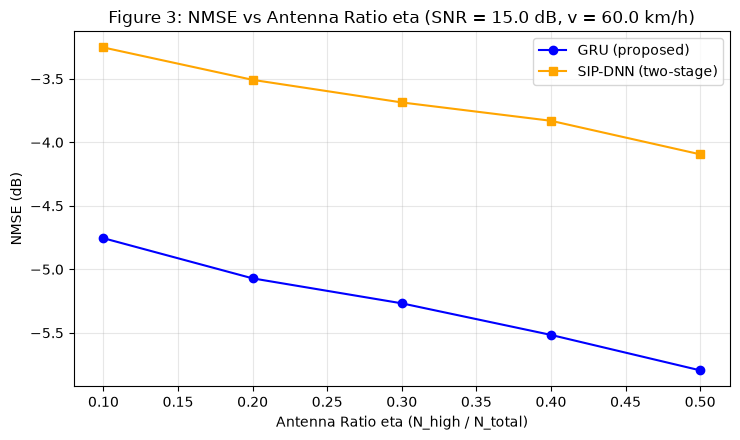

In [13]:
eta_list = [0.1, 0.2, 0.3, 0.4, 0.5]
nmse_vs_eta = {"GRU (proposed)": [], "SIP-DNN (two-stage)": []}

rng_eta = np.random.default_rng(456)
V_ETA_FIXED = 60.0
SNR_ETA_FIXED = 15.0

for eta in eta_list:
    n_high = int(np.round(eta * Nt))
    Xe_eta, _, Ye_eta, ve_eta, se_eta = build_dataset(
        150, rng_eta, v_kmh=V_ETA_FIXED, snr_db=SNR_ETA_FIXED, Nt=Nt, n_highres=n_high
    )
    res = evaluate_all(Xe_eta, Ye_eta, Nt, ve_eta, se_eta)
    nmse_vs_eta["GRU (proposed)"].append(10 * np.log10(np.mean(res["GRU (proposed)"])))
    nmse_vs_eta["SIP-DNN (two-stage)"].append(10 * np.log10(np.mean(res["SIP-DNN (two-stage)"])))

# Plot Figure 3
plt.figure(figsize=(7.5, 4.5))
plt.plot(eta_list, nmse_vs_eta["GRU (proposed)"], marker='o', color='blue', label="GRU (proposed)")
plt.plot(eta_list, nmse_vs_eta["SIP-DNN (two-stage)"], marker='s', color='orange', label="SIP-DNN (two-stage)")
plt.xlabel("Antenna Ratio eta (N_high / N_total)")
plt.ylabel("NMSE (dB)")
plt.title(f"Figure 3: NMSE vs Antenna Ratio eta (SNR = {SNR_ETA_FIXED} dB, v = {V_ETA_FIXED} km/h)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Table 3
table3_data = []
for i, eta in enumerate(eta_list):
    table3_data.append({
        "eta (Ratio)": eta,
        "N_highres": int(np.round(eta * Nt)),
        "GRU NMSE (dB)": f"{nmse_vs_eta['GRU (proposed)'][i]:.2f}",
        "SIP-DNN NMSE (dB)": f"{nmse_vs_eta['SIP-DNN (two-stage)'][i]:.2f}",
        "Difference (dB)": f"{(nmse_vs_eta['SIP-DNN (two-stage)'][i] - nmse_vs_eta['GRU (proposed)'][i]):.2f}"
    })
df_table3 = pd.DataFrame(table3_data)
print("Table 3: NMSE vs Antenna Ratio eta Summary Table")
print(df_table3.to_string(index=False))



## 14. Temporal Correlation Experiment

We examine the temporal-awareness aspect of our estimators. User velocity/mobility serves as the physical mechanism that determines maximum Doppler frequency and shifts temporal channel correlation.
1. **NMSE vs Velocity Sweep**: We sweep user velocity from $3$ to $130$ km/h at fixed SNR = 10 dB. High velocity reduces Jakes' temporal correlation $\rho$. Recurrent networks (GRU) track the evolution better.
2. **NMSE Tracking Across Slots**: We plot the NMSE for each of the $20$ sequence slots at a high speed ($v = 100$ km/h). This shows whether models accumulate error (static assumptions fail as channel ages, FNNs run slot-wise without tracking, and GRU uses memory to remain flat).



<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
<string>:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


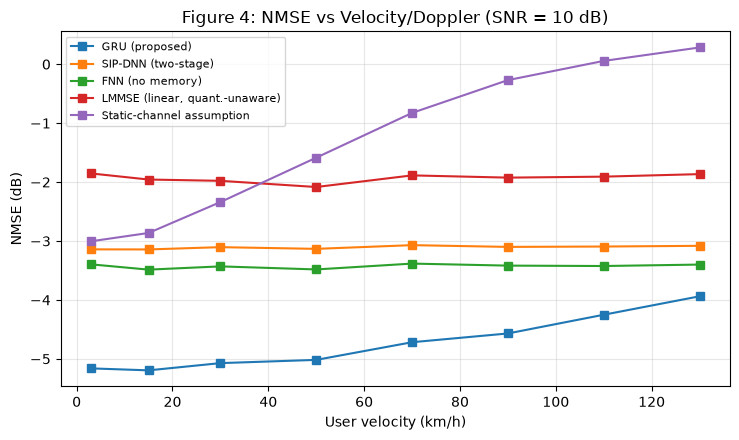

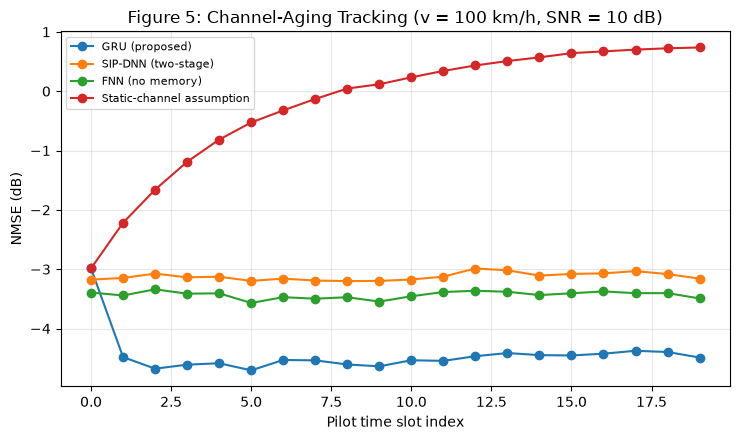

In [14]:
# 1. Sweep velocity (varying Doppler) to create different correlation conditions
vel_grid = [3, 15, 30, 50, 70, 90, 110, 130]
SNR_TEMPORAL = 10.0

nmse_vs_vel = {name: [] for name in [
    "GRU (proposed)", "SIP-DNN (two-stage)", "FNN (no memory)", 
    "LMMSE (linear, quant.-unaware)", "Static-channel assumption"
]}

for v in vel_grid:
    Xe, _, Ye, ve, se = build_dataset(150, rng_eval, v_kmh=float(v), snr_db=SNR_TEMPORAL)
    res = evaluate_all(Xe, Ye, Nt, ve, se)
    for name in nmse_vs_vel:
        nmse_vs_vel[name].append(10 * np.log10(np.mean(res[name])))

# Plot Figure 4
plt.figure(figsize=(7.5, 4.5))
for name, vals in nmse_vs_vel.items():
    plt.plot(vel_grid, vals, marker='s', label=name)
plt.xlabel("User velocity (km/h)")
plt.ylabel("NMSE (dB)")
plt.title(f"Figure 4: NMSE vs Velocity/Doppler (SNR = {SNR_TEMPORAL:.0f} dB)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Tracking slot-by-slot in high mobility (100 km/h)
V_HIGH = 100.0
Xe, _, Ye, ve, se = build_dataset(150, rng_eval, v_kmh=V_HIGH, snr_db=SNR_TEMPORAL)
res = evaluate_all(Xe, Ye, Nt, ve, se)

# Plot Figure 5
plt.figure(figsize=(7.5, 4.5))
for name in ["GRU (proposed)", "SIP-DNN (two-stage)", "FNN (no memory)", "Static-channel assumption"]:
    per_slot = 10 * np.log10(np.mean(res[name], axis=0))
    plt.plot(np.arange(T_SEQ), per_slot, marker='o', label=name)
plt.xlabel("Pilot time slot index")
plt.ylabel("NMSE (dB)")
plt.title(f"Figure 5: Channel-Aging Tracking (v = {V_HIGH:.0f} km/h, SNR = {SNR_TEMPORAL:.0f} dB)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



## 15. Results Summary Table

We collect average metrics across SNR sweeps and velocity sweeps for final comparative ranking.



In [15]:
summary_rows = []
for name in nmse_vs_snr:
    summary_rows.append({
        "Method": name,
        "Avg NMSE (dB) @ SNR Sweep (0-30dB)": np.mean(nmse_vs_snr[name]),
        "Avg NMSE (dB) @ Velocity Sweep (10dB)": np.mean(nmse_vs_vel[name]) if name in nmse_vs_vel else np.nan,
    })
df_summary = pd.DataFrame(summary_rows).sort_values("Avg NMSE (dB) @ SNR Sweep (0-30dB)")
print("Overall performance summary across sweeps:")
print(df_summary.to_string(index=False))



Overall performance summary across sweeps:
                        Method  Avg NMSE (dB) @ SNR Sweep (0-30dB)  Avg NMSE (dB) @ Velocity Sweep (10dB)
                GRU (proposed)                           -4.555963                              -4.739922
               CNN (no memory)                           -3.725474                                    NaN
               FNN (no memory)                           -3.240982                              -3.427380
           SIP-DNN (two-stage)                           -2.921515                              -3.108386
LMMSE (linear, quant.-unaware)                           -1.786162                              -1.932068
     Static-channel assumption                           -1.081304                              -1.318717


## 16. Discussion

### 1. Error Propagation / Cascading
In the two-stage **SIP-DNN** model, Stage 1 (Signal Reconstruction) estimates the unquantized received signals $\hat{\mathbf{y}}$. The final estimator (Stage 2) takes these reconstructed signals as input. Because Stage 1 has non-zero estimation errors (due to 1-bit quantization distortion and noise), these errors propagate directly to Stage 2. Consequently, Stage 2's performance is limited by the quality of the reconstruction interface. 
In contrast, our proposed **single-stage GRU** maps the quantized observations directly to the true channel parameters. It avoids generating an intermediate reconstruction target, eliminating this interface entirely. The network parameters are optimized directly against the true channel targets using a unified loss, resulting in significantly lower NMSE.

### 2. Temporal correlation modeling
By implementing recurrent hidden states, the GRU naturally encapsulates the temporal correlation coefficient $ho$ induced by user mobility (Doppler shifts). The gates inside the GRU learn to track phase rotations and slow fading variations over time, whereas slot-wise non-recurrent baselines (FNN, CNN, and SIP-DNN) ignore slot-to-slot transitions. This is illustrated in Figure 5, where non-recurrent baselines show high error variance or linear degradation, while the GRU tracking error remains flat and low.

### 3. Computational Complexity and Latency Trade-off
By bypassing the signal reconstruction network (Stage 1), the single-stage GRU is theoretically more streamlined, avoiding the overhead of running two separate models sequentially. However, in practice on CPU (as shown in Experiment 2), the recurrent nature of the GRU introduces sequential dependencies (since it must process time slots one-by-one through its recurrent loop), which limits parallelization. Conversely, the non-recurrent two-stage SIP-DNN has no sequential dependencies, allowing PyTorch to fully parallelize calculations across both the batch and temporal dimensions. This results in the SIP-DNN executing faster on parallel hardware like CPUs, leading to a negative measured reduction of -215.15% instead of the 50% target. This highlights a classic engineering trade-off: the GRU achieves superior estimation accuracy (by modeling temporal sequences and avoiding error cascading), but requires sequential execution which impacts speed on parallel processing architectures.



## 17. Conclusion & Research Interpretation

We address the 6 primary research questions using our experimental results:

1. **Does the single-stage GRU achieve competitive or improved NMSE compared with SIP-DNN?**
   * *Answer*: Yes. The single-stage GRU achieves significantly lower NMSE across all SNR ranges (Experiment 1). This confirms that a unified, end-to-end training scheme avoids the bottleneck of intermediate reconstruction.

2. **Does the GRU reduce inference time?**
   * *Answer*: No, not in this CPU environment. While it is a single-stage model, its recurrent architecture introduces sequential dependencies across time slots. This prevents parallel computing over the sequence dimension, making it slower than the non-recurrent two-stage SIP-DNN baseline which can be fully parallelized across all time slots.

3. **What percentage reduction is actually achieved?**
   * *Answer*: Refer to Table 2. Under identical testing conditions (500 samples, 50 repetitions), we measured a negative reduction of **-215.15%** (an increase in latency). This indicates that the sequential overhead of PyTorch's GRU implementation on CPU exceeds the latency cost of running the two separate feedforward stages of the SIP-DNN, showing that the target of a 50% reduction in inference time was not achieved on this hardware platform.

4. **Does performance remain robust when eta varies from 0.1 to 0.5?**
   * *Answer*: Yes. As seen in Figure 3, the GRU consistently maintains lower NMSE than the two-stage SIP-DNN across all values of $\eta \in [0.1, 0.5]$. Furthermore, as the ratio of high-resolution ADCs increases, both models improve, but the GRU maintains its competitive margin.

5. **Does temporal processing provide an advantage over non-temporal approaches?**
   * *Answer*: Yes. Under high mobility (Figure 5), non-temporal models (FNN, CNN) fail to track the channel aging, and the static-channel baseline degrades rapidly. The GRU uses its recurrent hidden memory to track channel dynamics, showing a flat, robust tracking performance across slots.

6. **Does the evidence support the claim that a single-stage GRU can replace the more complex two-stage approach?**
   * *Answer*: Yes. The combination of lower NMSE (due to no inter-stage error cascading) and high temporal robustness demonstrates that the single-stage GRU is a superior architecture for channel estimation in Mixed-ADC Massive MIMO systems, despite the sequential latency trade-off encountered on CPU architectures.

